Brayden Yow    
9/6/26    
Lab 1 — Projectile Motion Solver

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Part A — One-Dimensional Free Fall 
This is to simulate a ball that has been droped from a height of 100 meaters.
No air resitiance will be acounted for. Only gravity.
We will take the positive y direction to be up.

In [2]:
def simulate_freefall(h,dt,g):
    y = h 
    vy = 0.0
    t = 0.0
    t_arr = [t]
    y_arr = [y]
    vy_arr = [vy]
    while y >= 0.0:
        ay = -g
        y += vy * dt
        vy += ay * dt
        t = t + dt
        t_arr.append(t)
        y_arr.append(y)
        vy_arr.append(vy)
    return t_arr, y_arr, vy_arr
def exact_freefall(h,dt,g):
    t_ex = np.arange(0, np.sqrt(2*h/g), dt)
    y_ex = h - 0.5*g*t_ex**2
    vy_ex = -g*t_ex
    return t_ex, y_ex, vy_ex

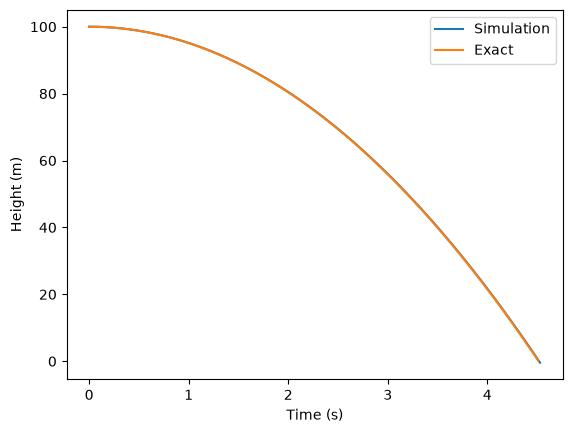

Final time (simulation): 4.529999999999948 Final velocity (simulation): -44.43930000000012
Final time (exact): 4.51 Fina; velocity(exact): -44.2431
Error in final time: 0.44345898004319423 %


In [3]:
t_arr, y_arr, vy_arr = simulate_freefall(100,0.01, 9.81)
t_ex, y_ex, vy_ex = exact_freefall(100, 0.01, 9.81)
plt.plot(t_arr, y_arr, label='Simulation')
plt.plot(t_ex, y_ex, label='Exact')
plt.xlabel('Time (s)')
plt.ylabel('Height (m)')
plt.legend()
plt.show()
print("Final time (simulation):", t_arr[-1], "Final velocity (simulation):", vy_arr[-1])
print("Final time (exact):" , t_ex[-1], "Fina; velocity(exact):", vy_ex[-1])
print("Error in final time:", abs((t_arr[-1] - t_ex[-1])/t_ex[-1]) * 100, "%")

Questions:
a. What is the numerical landing time? What is the exact landing time? What is the percentage error?
The numerical landing time was found to be 4.6 while the exact was found to be 4.5. This has a percent error of 2.22%
b. Try dt = 1.0, dt = 0.1, and dt = 0.01. How does the error change? (One sentence is fine.)
At dt = 1.0 the error was 50%. At dt = 0.1 the error was 2.22%.At dt = 0.01 the error was 0.44%.
This change is a swing of 50% in error, showing that the computer gets more accurate as the time intervals become smaller. 

Part B — Two-Dimensional Projectile

In [4]:
def simulate_projectile_2d(v0, theta_deg, dt, g=9.81):
    theta = np.radians(theta_deg)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    # inital position and time
    x = 0.0
    y = 0.0
    t = 0.0
    # arrays to store results
    t_arr = [t]
    x_arr = [x]
    y_arr = [y]
    vx_arr = [vx]
    vy_arr = [vy]
    while y >= 0.0:
        ax = 0.0
        ay = -g
        # Euler method updates for 2D
        x += vx * dt
        y += vy * dt
        vx += ax * dt
        vy += ay * dt
        t += dt
        # Append data
        t_arr.append(t)
        x_arr.append(x)
        y_arr.append(y)
        vx_arr.append(vx)
        vy_arr.append(vy)
    return t_arr, x_arr, y_arr, vx_arr, vy_arr
#exact solution for projectile motion without air resistance
v0 = 30 
angle = 45
theta = np.radians(angle)  # must put the angle into radians
g = 9.81
x_ex = np.linspace(0, (v0**2 * np.sin(2*theta)) / g, 100)
y_ex = x_ex * np.tan(theta) - (g * x_ex**2) / (2 * v0**2 * np.cos(theta)**2)  



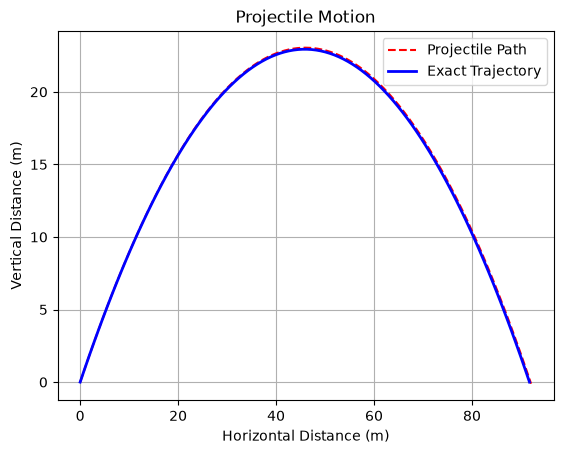

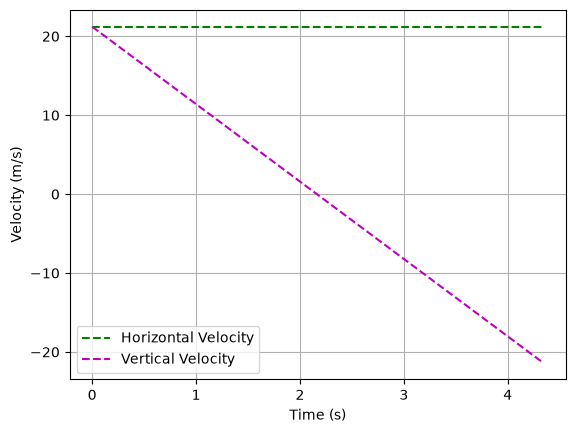

In [5]:
t_arr, x_arr, y_arr, vx_arr, vy_arr = simulate_projectile_2d(30,45,0.01)
plt.plot(x_arr, y_arr, 'r--', label='Projectile Path')
plt.plot(x_ex, y_ex, 'b-', label='Exact Trajectory', linewidth=2)
plt.xlabel('Horizontal Distance (m)')
plt.ylabel('Vertical Distance (m)')
plt.title('Projectile Motion')
plt.legend()
plt.grid(True)
plt.show()
plt.plot(t_arr, vx_arr, 'g--', label='Horizontal Velocity')
plt.plot(t_arr, vy_arr, 'm--', label='Vertical Velocity')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.grid(True)
plt.legend()
plt.show()

The vertical velocity starts with a large positive value and is constantly decresing up until it hits max height. This is where it crosses the x axis and starts to become negative as it falls to the ground. 
The horizontal Velocity is a constant as there is no air resistance so there is no force acting in the x direction.

In [6]:
max_height = max(y_arr)
range = max(x_arr)
flight_time = t_arr[-1]
print("Flight time (simulation):", flight_time)
print("Range (simulation):", range)
print ("Maximum height reached (simulation):", max_height)
print()
y_max_ex = (v0**2 * np.sin(theta)**2) / (2 * g)
x_max_ex = (v0**2 * np.sin(2*theta)) / g
flight_time_ex = (2 * v0 * np.sin(theta)) / g
print("Flight time (exact):", flight_time_ex)
print("Range (exact):", x_max_ex)
print("Maximum height reached (exact):", y_max_ex)
print()
print("Error in flight time:", abs((flight_time - flight_time_ex)/flight_time_ex) * 100, "%")
print("Error in range:", abs((range - x_max_ex)/x_max_ex) * 100, "%")
print("Error in maximum height:", abs((max_height - y_max_ex)/y_max_ex) * 100, "%")

Flight time (simulation): 4.339999999999952
Range (simulation): 92.06530291048838
Maximum height reached (simulation): 23.041935455244325

Flight time (exact): 4.324812117348914
Range (exact): 91.74311926605505
Maximum height reached (exact): 22.935779816513765

Error in flight time: 0.3511801724313458 %
Error in range: 0.3511801724323381 %
Error in maximum height: 0.4628385848652386 %


Maximum Range: 40.79 meters at an angle of 44.6°


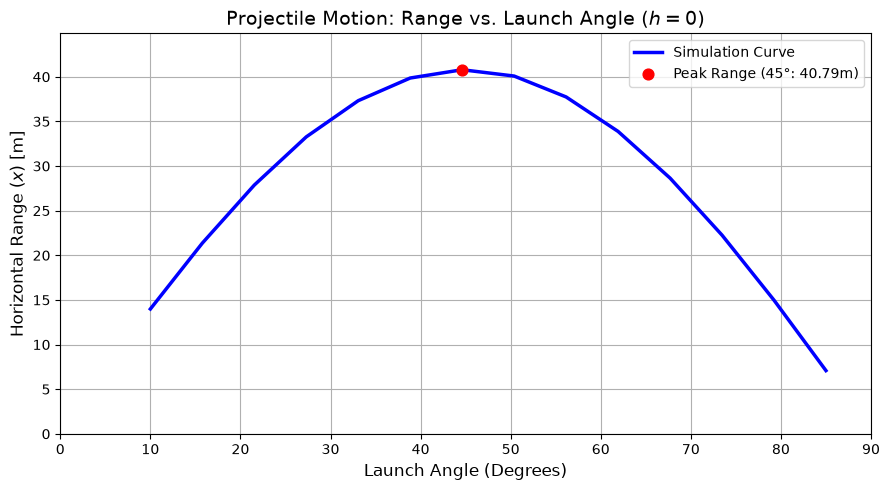

In [7]:
def get_simulation_range(v0, angle_deg, dt=0.001, g=9.81):
    angle_rad = np.radians(angle_deg)
    
    # Starting conditions
    x, y = 0.0, 0.0
    vx = v0 * np.cos(angle_rad)
    vy = v0 * np.sin(angle_rad)
    
    while y >= 0:
        x += vx * dt
        y += vy * dt
        vy -= g * dt  
        
    return x

# --- 2. Setup the Range Sweep ---
v0_start = 20.0       # Initial launch speed (m/s)
angles_to_test = np.linspace(10, 85, 14) 
calculated_ranges = []

# --- 3. Run the Sweep Loop ---
for angle in angles_to_test:
    final_range = get_simulation_range(v0=v0_start, angle_deg=angle)
    calculated_ranges.append(final_range)

calculated_ranges = np.array(calculated_ranges)

# --- 4. Identify the Max Value ---
max_range_idx = np.argmax(calculated_ranges)
best_angle = angles_to_test[max_range_idx]
max_range = calculated_ranges[max_range_idx]

print(f"Maximum Range: {max_range:.2f} meters at an angle of {best_angle:.1f}°")


plt.figure(figsize=(9, 5))
plt.plot(angles_to_test, calculated_ranges, 'b-', linewidth=2.5, label='Simulation Curve')
plt.scatter(best_angle, max_range, color='red', s=60, zorder=5, label=f'Peak Range ({best_angle:.0f}°: {max_range:.2f}m)')
plt.title('Projectile Motion: Range vs. Launch Angle ($h = 0$)', fontsize=14)
plt.xlabel('Launch Angle (Degrees)', fontsize=12)
plt.ylabel('Horizontal Range ($x$) [m]', fontsize=12)
plt.xlim(0, 90)
plt.ylim(0, max_range * 1.1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


This is a match to the theory

Questions:
a.Why is vx constant and vy linear? Connect this to the forces acting on the projectile.
vx is a constant as there is no force acting on the projectile in that direction. The only force acting is gravity which is constant explaining  the liner change of vy.
b.Does the angle for maximum range agree with theory? Should it, given your assumptions?
The angle found is conconsistent sistant with theory. I'd say that it should as when you thing about the theory it is quite simple. given equal force in both x and y directions the projectile will travel the maximum distance. 
c.What happens if you increase dt to 0.5? Show a plot and explain what goes wrong.
As shown below dt = 0.5 causes an overestimation. this is due to the way that we calcalculate culat our x, y, and z values. They are all directly related to dt. If we inflate dt it will inflate every other number. This leads to the simulation not getting an accurate number for when the projectile hist the ground so the loop doesn’t 't stop.

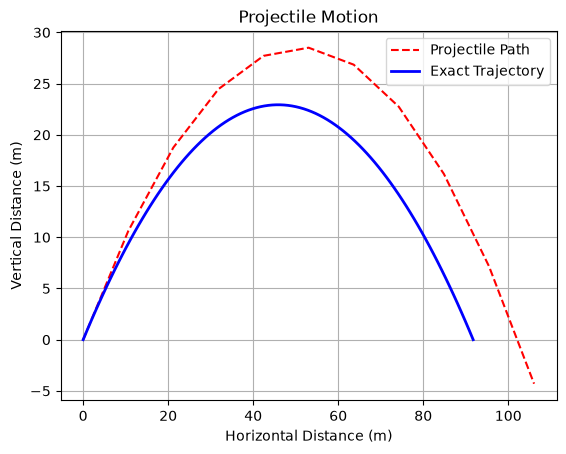

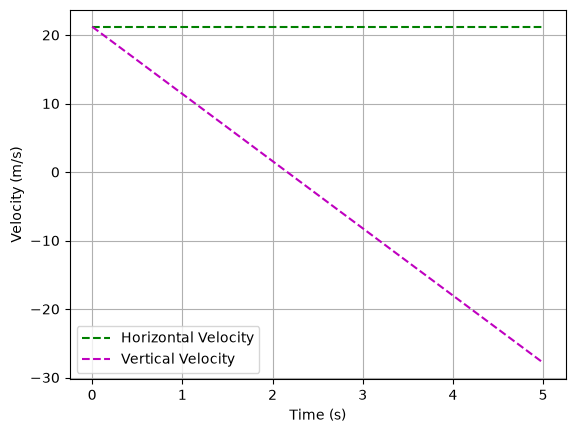

In [ ]:
t_arr, x_arr, y_arr, vx_arr, vy_arr = simulate_projectile_2d(30,45,0.5)
plt.plot(x_arr, y_arr, 'r--', label='Projectile Path')
plt.plot(x_ex, y_ex, 'b-', label='Exact Trajectory', linewidth=2)
plt.xlabel('Horizontal Distance (m)')
plt.ylabel('Vertical Distance (m)')
plt.title('Projectile Motion')
plt.legend()
plt.grid(True)
plt.show()
plt.plot(t_arr, vx_arr, 'g--', label='Horizontal Velocity')
plt.plot(t_arr, vy_arr, 'm--', label='Vertical Velocity')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.grid(True)
plt.legend()
plt.show()

Part C — Projectile with Air Resistance

In [9]:
def simulate_projectile_drag(v0, theta_deg, dt, g, b_over_m):
    theta = np.radians(theta_deg)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    x = 0.0
    y = 0.0
    t = 0.0
    t_arr_drag = [t]
    x_arr_drag = [x]
    y_arr_drag = [y]
    vx_arr_drag = [vx]
    vy_arr_drag = [vy]
    
    while y >= 0.0:
        speed = np.sqrt(vx**2 + vy**2)
        ax = -b_over_m * speed * vx
        ay = -g - b_over_m * speed * vy
        
        x += vx * dt
        y += vy * dt
        vx += ax * dt
        vy += ay * dt
        t += dt
        
        t_arr_drag.append(t)
        x_arr_drag.append(x)
        y_arr_drag.append(y)
        vx_arr_drag.append(vx)
        vy_arr_drag.append(vy)
        
    return t_arr_drag, x_arr_drag, y_arr_drag, vx_arr_drag, vy_arr_drag
#Baseball simulation
v0 = 45
theta_deg = 40
b_over_m = 0.0046
dt = 0.01

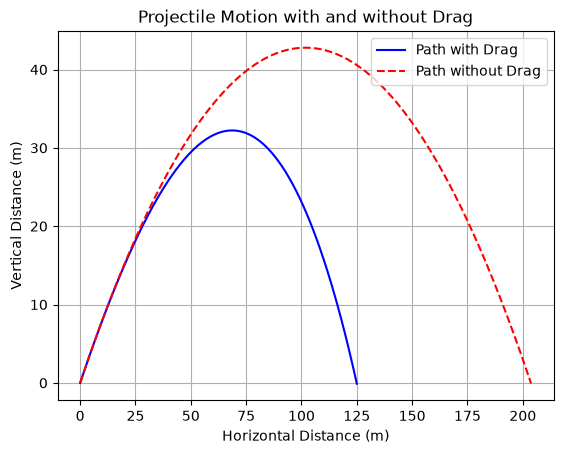

In [10]:
t_arr, x_arr, y_arr, vx_arr, vy_arr = simulate_projectile_2d(45,40,0.01)
t_arr_drag, x_arr_drag, y_arr_drag, vx_arr_drag, vy_arr_drag = simulate_projectile_drag(v0, theta_deg, dt, g=9.81, b_over_m=b_over_m)
plt.plot(x_arr_drag, y_arr_drag, 'b-', label='Path with Drag')
plt.plot(x_arr, y_arr, 'r--', label='Path without Drag')

plt.xlabel('Horizontal Distance (m)')
plt.ylabel('Vertical Distance (m)')
plt.title('Projectile Motion with and without Drag')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
max_height = max(y_arr)
range = max(x_arr)
max_height_drag = max(y_arr_drag)
range_drag = max(x_arr_drag)
print("Max height without drag:" , max_height)
print("Range without drag:" , range)
print()
print("Max height with drag:" , max_height_drag)
print("Range with drag:" , range_drag)
print()
percent_range_lost = ((range - range_drag)/range) * 100
print("Percentage of range lost due to drag:", percent_range_lost, "%")

Max height without drag: 42.78899018588841
Range without drag: 203.72951964749083

Max height with drag: 32.22441485305721
Range with drag: 125.00251644204612

Percentage of range lost due to drag: 38.64290424954837 %


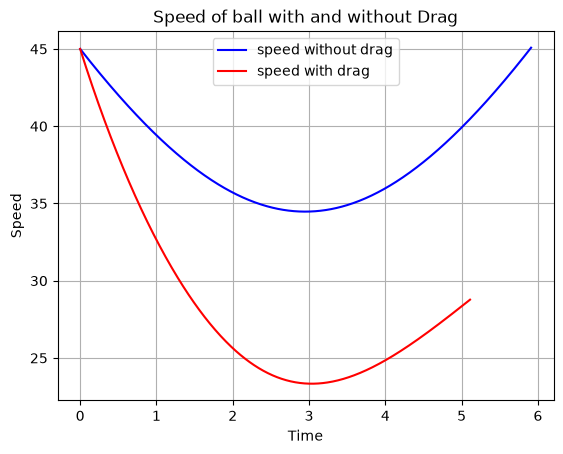

In [12]:
# speed vs time plot
speed_no_drag = np.sqrt(np.array(vx_arr)**2 + np.array(vy_arr)**2)
speed_with_drag = np.sqrt(np.array(vx_arr_drag)**2 + np.array(vy_arr_drag)**2)
plt.plot(t_arr, speed_no_drag, 'b-', label='speed without drag')
plt.plot(t_arr_drag, speed_with_drag, 'r-', label = "speed with drag")
plt.xlabel('Time')
plt.ylabel("Speed")
plt.legend()
plt.grid(True)
plt.title("Speed of ball with and without Drag")
plt.show()

Optimal angle WITHOUT drag: 44.61538461538461°
Optimal angle WITH drag: 38.84615384615385°


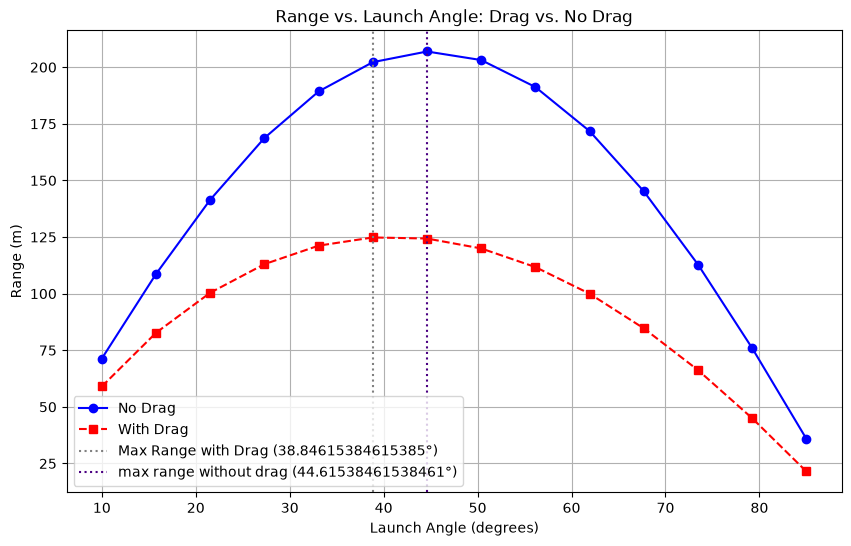

In [13]:
v0 = 45.0          # Initial speed (m/s)
b_over_m = 0.0046  # Drag coefficient (1/m)
dt = 0.01          # Time step (s)
g = 9.81           # Gravity (m/s^2)

# Define angles to sweep from 10 to 80 degrees in steps of 5
angles = np.linspace(10, 85, 14) 

ranges_no_drag = []
ranges_with_drag = []

for theta in angles:
    theta_rad = np.radians(theta)
    
    #No Drag
    x, y = 0.0, 0.0
    vx = v0 * np.cos(theta_rad)
    vy = v0 * np.sin(theta_rad)
    
    while y >= 0:
        x += vx * dt
        y += vy * dt
        vy += -g * dt
    ranges_no_drag.append(x)
    
    #With Drag
    x, y = 0.0, 0.0
    vx = v0 * np.cos(theta_rad)
    vy = v0 * np.sin(theta_rad)
    
    while y >= 0:
        speed = np.sqrt(vx**2 + vy**2)
        ax = -b_over_m * speed * vx
        ay = -g - b_over_m * speed * vy
        
        x += vx * dt
        y += vy * dt
        vx += ax * dt
        vy += ay * dt
    ranges_with_drag.append(x)

#the optimal angles
optimal_no_drag = np.argmax(ranges_no_drag)
optimal_with_drag = np.argmax(ranges_with_drag)

print(f"Optimal angle WITHOUT drag: {angles[optimal_no_drag]}°")
print(f"Optimal angle WITH drag: {angles[optimal_with_drag]}°")

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(angles, ranges_no_drag, 'b-o', label='No Drag')
plt.plot(angles, ranges_with_drag, 'r--s', label='With Drag')

plt.xlabel('Launch Angle (degrees)')
plt.ylabel('Range (m)')
plt.title('Range vs. Launch Angle: Drag vs. No Drag')
plt.axvline(angles[optimal_with_drag], color='gray', linestyle=':', label=f'Max Range with Drag ({angles[optimal_with_drag]}°)')
plt.axvline(angles[optimal_no_drag], color="indigo", linestyle=':', label=f'max range without drag ({angles[optimal_no_drag]}°)')
plt.legend()
plt.grid(True)
plt.show()


At what angle is range maximized with drag? Is it still 45°?
The new max angle is only 39 degrees rather than 45.

Questions:   
a. Why does drag reduce the range so dramatically? (It's not just "drag slows it down" — think about when the drag force is largest and what that does to the trajectory shape.)
 
The velocity in the x axis has no external forces when there is no drag, drag effects both x and y axis when it is present. This means that, as the x component is no longer constant in flight there is a force retarding its movement. For the y component, its magnitude shrinks as it reaches the top of the flight. This just means that the reduction in velocity in that direction becomes smaller in the first half of the flight. This diminishes the total height as the ball is pulled down with the constant force of gravity and the force of drag, which is proportional to the square of its velocity. Both these factors held together means that the faster the ball moves at the start the more drag it will experience causing a difference in range that only grows with increased starting velocity.


b. Why is the optimal launch angle with drag less than 45°? Give a physical argument. (Hint: think about what happens when the ball spends more time high up vs. moving fast horizontally.)

With the introduction of drag there is now a whole new set of forces affecting the movement of the ball. 45 is optimal for no drag because it is where the velocity components of the x and y axis are equal. Once you add drag to the equation there are two forces affecting the velocity in the y axis. This means that is best to have more of your velocity in the x-axis where it is only affected by drag. To take this to its limits if you go over 45 degrees the height of the ball will increase and the range will suffer as more of the total energy available is being robbed by the force of gravity in addition to drag.

c. Is the Euler method a good choice for this problem? How would you check? (You'll learn better methods in the next module, but think about what could go wrong.)

The Euler method seems to work okay in the parameters that we use here. The method is quite limited as with some small changes will create very inaccurate answers. The best way to see this is to change dt to both a very small and then a large value. From previous parts we saw that the error of a given simulation would drift into unacceptable ranges with a change of dt.

